# Extraction et visualisation des données
## Installation des bibliothèques

In [ ]:
import pandas as pd # Pandas est une bibliothèque puissante pour la manipulation et l'analyse de données, surtout sous forme de tableaux (DataFrames).
import numpy as np # NumPy est une bibliothèque fondamentale pour le calcul scientifique en Python
import matplotlib.pyplot as plt # Matplotlib est une bibliothèque de visualisation graphique
from statsmodels.tsa.seasonal import seasonal_decompose # seasonal_decompose permet de décomposer une série temporelle en ses composantes (tendance, saisonnalité, résidus)
from sklearn.linear_model import LinearRegression # Effectuer une régression linéaire pour modéliser la relation entre une variable dépendante et une ou plusieurs variables indépendantes


/home/cytech/.local/lib/python3.12/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.9.0' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/home/cytech/.local/lib/python3.12/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


ModuleNotFoundError: No module named 'statsmodels'

## Lecture des données

In [33]:
data = pd.read_csv('autoroute.csv', sep=";", index_col=0)
data.describe()

,mois,a061,a062,a007,a040,a043,a048,a100,a101,a102,a111,a112,a113,a081,a001,a004,a013,a711,a712
count,85.000000,85.000000,85.000000,85.000000,85.000000,85.000000,85.000000,85.000000,85.000000,85.000000,85.000000,85.000000,85.000000,85.000000,85.000000,85.000000,85.000000,85.000000,85.000000
mean,6.529412,26495.129412,40826.988235,38933.070588,11445.282353,28898.282353,16892.047059,58474.823529,23911.423529,16089.717647,24137.717647,10848.858824,11212.882353,13945.188235,36288.200000,14060.600000,23759.176471,13021.494118,9773.482353
std,3.462686,6342.831035,13764.911676,14834.629291,3137.669338,4251.538124,3294.623744,12856.114120,8419.688378,8156.374423,6187.586039,3042.588329,5143.365462,4449.435939,5068.152995,2147.717311,4458.415596,4362.765993,4154.593687
min,1.000000,17487.000000,22955.000000,21328.000000,6167.000000,21244.000000,11051.000000,37480.000000,13513.000000,8040.000000,13699.000000,5823.000000,0.000000,7274.000000,26396.000000,9456.000000,15130.000000,6539.000000,4331.000000
25%,4.000000,22095.000000,30712.000000,27137.000000,9365.000000,25973.000000,14324.000000,48339.000000,17699.000000,10361.000000,19120.000000,8586.000000,9548.000000,10430.000000,32753.000000,12400.000000,20587.000000,10070.000000,7036.000000
50%,7.000000,25085.000000,39086.000000,34225.000000,10619.000000,28306.000000,17119.000000,57763.000000,21753.000000,13110.000000,23257.000000,10389.000000,11766.000000,12968.000000,36873.000000,14296.000000,23499.000000,12431.000000,8773.000000
75%,9.000000,28898.000000,43951.000000,43874.000000,13362.000000,31512.000000,18874.000000,63904.000000,26021.000000,16926.000000,27591.000000,12809.000000,14365.000000,15931.000000,39165.000000,15619.000000,27312.000000,14958.000000,10822.000000
max,12.000000,43858.000000,74588.000000,74559.000000,19106.000000,40551.000000,23527.000000,89629.000000,44840.000000,38283.000000,38542.000000,18363.000000,20946.000000,25422.000000,48240.000000,18581.000000,34006.000000,25567.000000,22486.000000


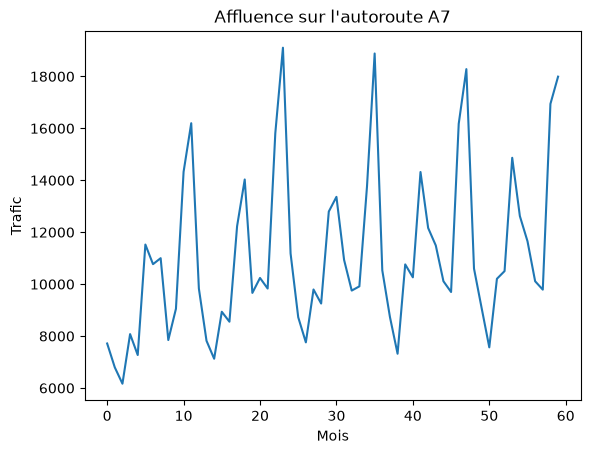

In [34]:
# Extraction de la colonne d'intérêt (4ème colonne)
M = data.to_numpy()[:, 4]

# Séparation des données en ensembles d'apprentissage et de test
train = M[:60] 
test = M[60:-1] # On enlève le dernier mois sur les données test pour avoir des années complètes


# Visualisation des données, ajout des titres et labels
plt.plot(train)
plt.title("Affluence sur l'autoroute A7")
plt.xlabel("Mois")
plt.ylabel("Trafic")
plt.show()

# 1.
# Analyse du graphique : on peut observer une structure qui se répète à intervalles réguliers (des pics), la période est de 12 mois. De plus, on observe une tendance légèrement
# haussière sur les 5 années prises en compte. Ce n'est pas surprenant, cela pourrait correspondre aux mois de vacances estivales.

# Décomposition saisonnière

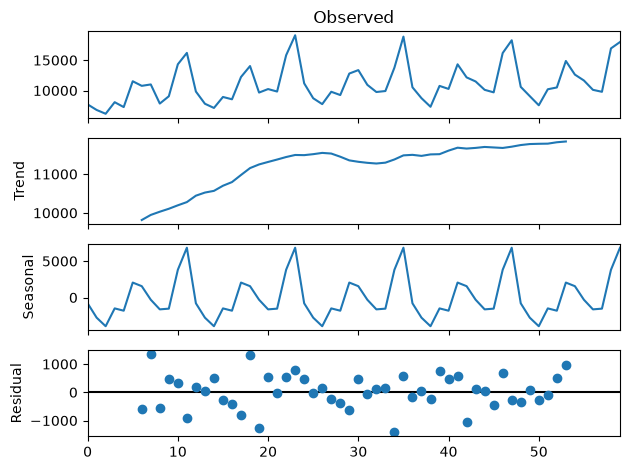

In [35]:
decomp = seasonal_decompose(train, model='additive', period=12)
decomp.plot()

# Extraction de la tendance (en supprimant les valeurs NaN) 
tendance = decomp.trend[~np.isnan(decomp.trend)]

# 2.
# Nous avons appliqué un modèle additif avec une période de 12 mois, car l'amplitude des pics est globalement constante dans le temps.
# Cette décomposition permet d'isoler clairement la tendance à la hausse et la saisonnalité annuelle, tout en obtenant des résidus stables autour de zéro.


# Régression linéaire sur la tendance
## Préparation des données pour la régression linéaire

In [36]:
time = np.arange(len(tendance)) + 6  # permet de mettre la valeur de time à 6 (et non pas 0 si on n'avait pas mis +6
time = time.reshape(-1, 1)  # Format adapté pour .fit car il lui faut un tableau 2D alors que time était un vecteur 1D

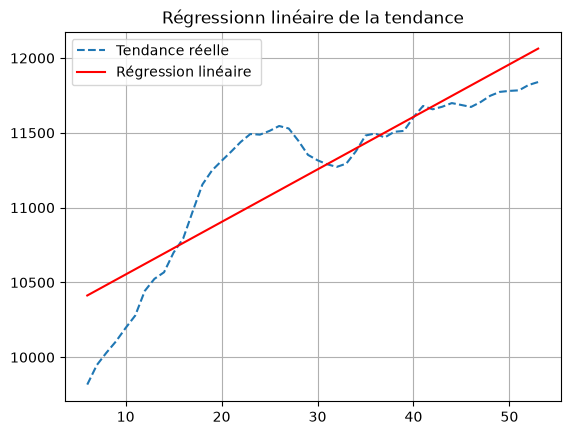

In [37]:
model = LinearRegression() # Créé un objet régression linéaire
#Instanciation :
#Cette commande crée une instance (un objet) de la classe LinearRegression. model est le nom que vous donnez à cet objet. Vous pouvez utiliser n'importe quel nom (par exemple, regression, lr, etc.).
#À ce stade, le modèle est vide : il n'a pas encore été entraîné sur des données.

model.fit(time,tendance) # Ajuste un modèle linéaire de la tendance en fonction du temps
tendance_pred = model.predict(time)

# Coefficients de la régression y=ax+b
a = model.coef_[0] 
b = model.intercept_ 

# Affichage de la régression linéaire
# plt.figure(figsize=(10, 6)) par exemple, si l'on veut définir la taille de la figure largeur * hauteur
plt.plot(np.arange(len(tendance)) + 6, tendance, label="Tendance réelle ", linestyle="--")
plt.plot(np.arange(len(tendance)) + 6, tendance_pred, label="Régression linéaire ", color='red')
plt.legend()
plt.title("Régressionn linéaire de la tendance")
plt.grid(True)

# 3.
# Cette régression linéaire esr discutable, il y a un ecart de prédiction important (principalement entre le mois 28 et 40 ) 
# elle ne parvient pas à capter les dynamiques complexes de la tendance réelle.

# Prévision et comparaison

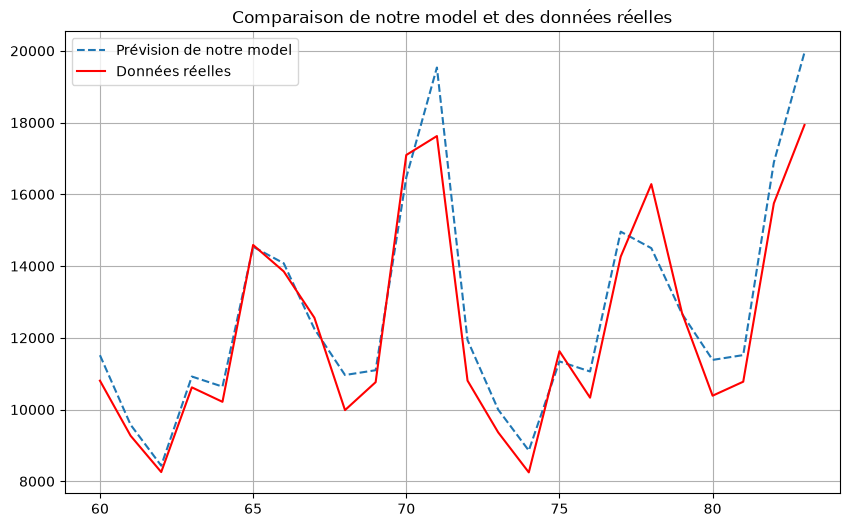

In [38]:
# Prévision
time_prev = np.arange(60, 84) 

tendance_prev = a * time_prev + b
# Calcul de la tendance future en prolongeant la droite de régression (y = ax + b).

saison_prev = np.tile(decomp.seasonal[:12], 2)
# Création de la saisonnalité future en dupliquant le motif annuel de 12 mois sur 2 ans

prevision = tendance_prev + saison_prev
# Calcul de la prévision finale en additionnant la tendance et la saisonnalité (modèle additif).

# Comparaison avec les observations
plt.figure(figsize=(10, 6))
plt.plot(time_prev, prevision, label="Prévision de notre model", linestyle="--")
plt.plot(time_prev, test, label="Données réelles", color='red')
plt.legend()
plt.title("Comparaison de notre model et des données réelles")
plt.grid(True)

# Commentaire : notre model predit avec précision les données des 2 dernières années.Le modèle est très performant et parvient à reproduire fidèlement la dynamique des données réelles